# PCA și K-Means — Partea 1
**Responsabilitate:** pregătirea datelor, reducerea dimensionalității (PCA), matricea de loadings și testarea pe date noi.

| Task | Conținut |
|---|---|
| 1.1 | Citire, encoding, variante de scalare (Min-Max, Standard, log) |
| 1.2 | PCA complet, varianța explicată per componentă |
| 1.3 | Nr. de componente pentru 98 / 95 / 90 / 80 %, grafic cumulativ |
| 1.4 | Matricea de loadings + heatmap |
| 1.5 | Case fictive, pipeline de inferență, explicație teoretică |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder, MinMaxScaler, StandardScaler, FunctionTransformer
)
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Task 1.1 — Citirea și pregătirea datelor

In [2]:
# Citim datasetul curățat.
# keep_default_na=False: textul "None" (= fără garaj, fără subsol etc.) rămâne text, nu devine NaN.
df = pd.read_csv("data/AmesHousing_cleaned.csv", keep_default_na=False, na_values=[""])

print("Dimensiuni:", df.shape)
print("Valori lipsă:", int(df.isna().sum().sum()))

# MS SubClass e nominală (20, 30, 60 nu au ordine) -> o tratăm ca text
df["MS SubClass"] = df["MS SubClass"].astype(str)

Dimensiuni: (2925, 82)
Valori lipsă: 0


In [3]:
# Ținta de preț și cele 6 clase din laboratorul anterior (le păstrăm pentru bonusul b)
bins = [-np.inf, 100_000, 130_000, 180_000, 250_000, 400_000, np.inf]
class_names = ["<100k", "100k-130k", "130k-180k", "180k-250k", "250k-400k", ">=400k"]

y_price = df["SalePrice"].copy()
y_class = pd.cut(y_price, bins=bins, labels=class_names, right=False)
y_class_codes = y_class.cat.codes

print(y_class.value_counts().reindex(class_names))

SalePrice
<100k         237
100k-130k     509
130k-180k    1036
180k-250k     684
250k-400k     397
>=400k         62
Name: count, dtype: int64


In [4]:
# PCA e nesupervizat: scoatem ținta și identificatorii din predictori
id_cols = [c for c in ["PID", "Order"] if c in df.columns]
X_raw = df.drop(columns=["SalePrice"] + id_cols).copy()

# bool -> int (ca să nu apară probleme la encoding)
bool_cols = X_raw.select_dtypes(include="bool").columns
X_raw[bool_cols] = X_raw[bool_cols].astype(int)

numeric_features = X_raw.select_dtypes(include="number").columns.tolist()
categorical_features = [c for c in X_raw.columns if c not in numeric_features]

# plasă de siguranță pentru eventuale valori lipsă rămase
for c in X_raw.columns[X_raw.isna().any()]:
    X_raw[c] = X_raw[c].fillna(
        X_raw[c].median() if c in numeric_features else X_raw[c].mode()[0]
    )

print("Caracteristici numerice:", len(numeric_features))
print("Caracteristici categorice:", len(categorical_features))

Caracteristici numerice: 48
Caracteristici categorice: 31


**Encoding.** Variabilele de calitate (Po…Ex) sunt deja ordinale numerice (0–5) din curățare. Variabilele nominale (cartier, tip de garaj etc.) primesc One-Hot Encoding. One-Hot se face în pipeline, ca să putem aplica exact aceeași transformare și pe case noi.

In [5]:
# Care coloane numerice merită logaritmate? Doar cele continue (multe valori distincte),
# nenegative și puternic asimetrice. Nu logaritmăm indicatori 0/1 sau scale ordinale.
skew = X_raw[numeric_features].skew()
log_features = [
    c for c in numeric_features
    if X_raw[c].nunique() > 15 and X_raw[c].min() >= 0 and skew[c] > 0.75
]

skew_table = pd.DataFrame({
    "skew înainte": X_raw[log_features].skew(),
    "skew după log1p": np.log1p(X_raw[log_features]).skew(),
}).sort_values("skew înainte", ascending=False)

print("Coloane logaritmate:", len(log_features))
display(skew_table.round(2))

Coloane logaritmate: 18


,skew înainte,skew după log1p
Misc Val,22.23,5.23
Lot Area,13.20,-0.53
Low Qual Fin SF,12.11,8.57
3Ssn Porch,11.39,8.84
BsmtFin SF 2,4.14,2.45
Enclosed Porch,4.01,1.97
Screen Porch,3.95,2.95
Mas Vnr Area,2.58,0.54
Open Porch SF,2.50,-0.04
Wood Deck SF,1.85,0.16


In [7]:
def build_pipeline(scaler, use_log=False):
    """Encoding + (opțional log1p) + scalare, într-un singur pipeline refolosibil."""
    log_cols = log_features if use_log else []
    other_num = [c for c in numeric_features if c not in log_cols]

    transformers = []
    if log_cols:
        transformers.append((
            "log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), log_cols
        ))
    transformers.append(("num", "passthrough", other_num))
    transformers.append((
        "cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features
    ))

    prep = ColumnTransformer(transformers, verbose_feature_names_out=False)
    return Pipeline([("prep", prep), ("scaler", scaler)])


pipelines = {
    "Min-Max":        build_pipeline(MinMaxScaler()),
    "Standard":       build_pipeline(StandardScaler()),
    "Log + Min-Max":  build_pipeline(MinMaxScaler(), use_log=True),
    "Log + Standard": build_pipeline(StandardScaler(), use_log=True),
}

X_scaled = {}
for name, pipe in pipelines.items():
    X_scaled[name] = pipe.fit_transform(X_raw)
    assert not np.isnan(X_scaled[name]).any(), f"NaN în {name}"

MAIN = "Min-Max"   # varianta principală cerută de enunț
feature_names = pipelines[MAIN].named_steps["prep"].get_feature_names_out()

print("Forma după encoding + scalare:")
for name, arr in X_scaled.items():
    print(f"  {name:15s} {arr.shape}")

Forma după encoding + scalare:
  Min-Max         (2925, 277)
  Standard        (2925, 277)
  Log + Min-Max   (2925, 277)
  Log + Standard  (2925, 277)


## Task 1.2 — PCA complet și varianța explicată per componentă

In [9]:
# PCA cu toate componentele, pentru fiecare variantă de scalare
pca_full = {name: PCA(random_state=RANDOM_STATE).fit(arr) for name, arr in X_scaled.items()}
pca_main = pca_full[MAIN]

evr = pca_main.explained_variance_ratio_
pc_table = pd.DataFrame({
    "Componentă": [f"PC{i+1}" for i in range(len(evr))],
    "Varianță explicată": evr,
    "Varianță cumulată": np.cumsum(evr),
})
print(f"Total componente: {len(evr)}  |  suma proporțiilor: {evr.sum():.4f}")
display(pc_table.head(15).round(4))

Total componente: 277  |  suma proporțiilor: 1.0000


,Componentă,Varianță explicată,Varianță cumulată
0,PC1,0.1214,0.1214
1,PC2,0.0731,0.1945
2,PC3,0.0442,0.2387
3,PC4,0.0350,0.2737
4,PC5,0.0330,0.3066
5,PC6,0.0295,0.3362
6,PC7,0.0253,0.3614
7,PC8,0.0250,0.3864
8,PC9,0.0227,0.4092
9,PC10,0.0217,0.4308


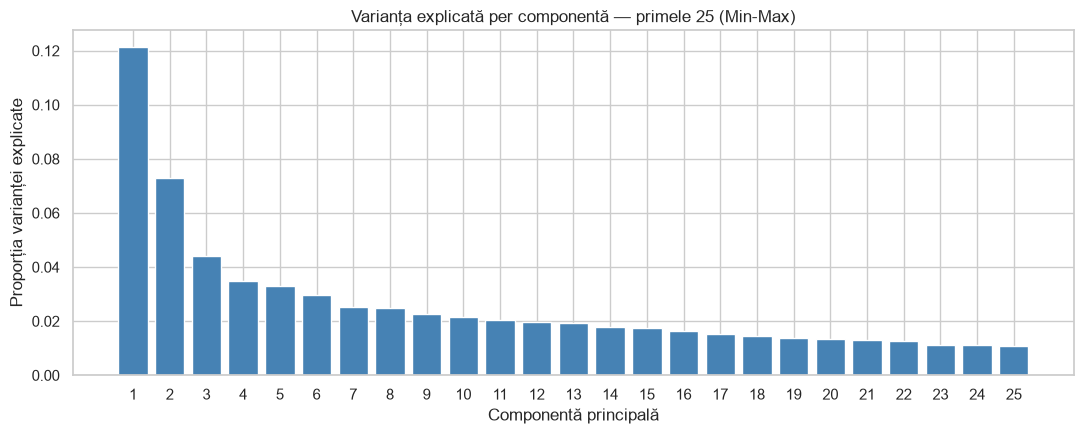

In [10]:
n_show = 25
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(range(1, n_show + 1), evr[:n_show], color="steelblue")
ax.set_xlabel("Componentă principală")
ax.set_ylabel("Proporția varianței explicate")
ax.set_title(f"Varianța explicată per componentă — primele {n_show} (Min-Max)")
ax.set_xticks(range(1, n_show + 1))
plt.tight_layout()
plt.show()

## Task 1.3 — Câte componente pentru 98 / 95 / 90 / 80 % din varianță?

In [12]:
thresholds = [0.98, 0.95, 0.90, 0.80]

n_components = {}   # n_components[variantă][prag] = nr. de componente
rows = []
for name, p in pca_full.items():
    cum = np.cumsum(p.explained_variance_ratio_)
    n_components[name] = {t: int(np.searchsorted(cum, t) + 1) for t in thresholds}
    row = {"Scalare": name, "Features după encoding": X_scaled[name].shape[1]}
    row.update({f"{int(t*100)}%": n_components[name][t] for t in thresholds})
    rows.append(row)

components_table = pd.DataFrame(rows).set_index("Scalare")
display(components_table)

# Verificare: PCA(n_components=prag) trebuie să dea același număr
for t in thresholds:
    k_check = PCA(n_components=t, svd_solver="full").fit(X_scaled[MAIN]).n_components_
    assert k_check == n_components[MAIN][t], (t, k_check)
print("Verificare cu PCA(n_components=prag): OK")

,Features după encoding,98%,95%,90%,80%
Scalare,,,,,
Min-Max,277,131,97,71,45
Standard,277,192,170,147,112
Log + Min-Max,277,132,98,72,46
Log + Standard,277,190,169,146,111


Verificare cu PCA(n_components=prag): OK


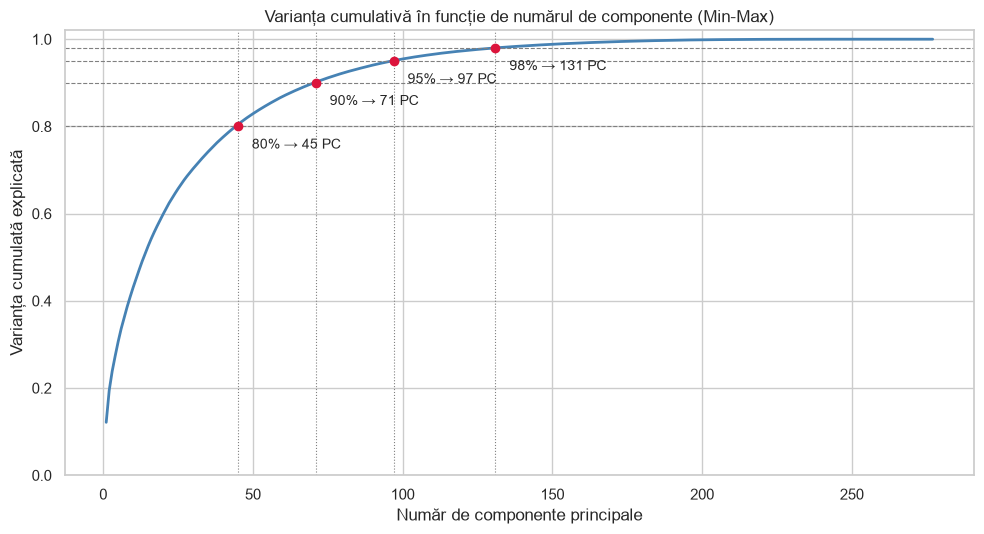

In [13]:
# Graficul varianței cumulative (Min-Max) cu pragurile marcate
cum_main = np.cumsum(pca_main.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(range(1, len(cum_main) + 1), cum_main, lw=2, color="steelblue")
for t in thresholds:
    k = n_components[MAIN][t]
    ax.axhline(t, ls="--", color="gray", lw=0.8)
    ax.axvline(k, ls=":", color="gray", lw=0.8)
    ax.scatter(k, t, color="crimson", zorder=5)
    ax.annotate(f"{int(t*100)}% → {k} PC", (k, t),
                textcoords="offset points", xytext=(10, -16), fontsize=10)
ax.set_xlabel("Număr de componente principale")
ax.set_ylabel("Varianța cumulată explicată")
ax.set_title("Varianța cumulativă în funcție de numărul de componente (Min-Max)")
ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.show()

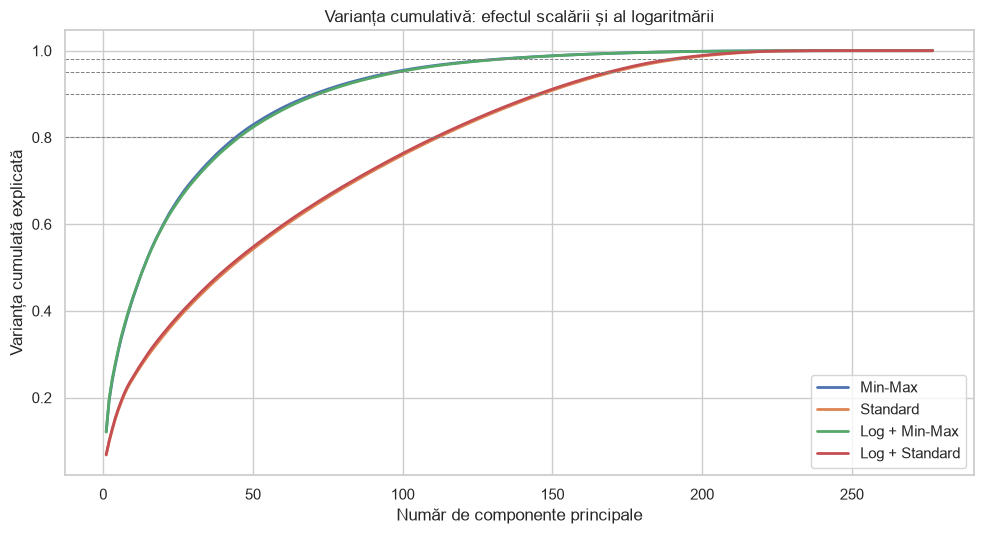

In [14]:
# Comparație între variantele de scalare
fig, ax = plt.subplots(figsize=(10, 5.5))
for name, p in pca_full.items():
    c = np.cumsum(p.explained_variance_ratio_)
    ax.plot(range(1, len(c) + 1), c, lw=2, label=name)
for t in thresholds:
    ax.axhline(t, ls="--", color="gray", lw=0.7)
ax.set_xlabel("Număr de componente principale")
ax.set_ylabel("Varianța cumulată explicată")
ax.set_title("Varianța cumulativă: efectul scalării și al logaritmării")
ax.legend()
plt.tight_layout()
plt.show()

In [15]:
# Seturile reduse (scorurile PC) pentru fiecare variantă și prag -> le folosește K-Means
Z_full = {name: pca_full[name].transform(X_scaled[name]) for name in pca_full}

reduced = {
    (name, t): Z_full[name][:, :n_components[name][t]]
    for name in pca_full for t in thresholds
}

for t in thresholds:
    print(f"{int(t*100)}%: {reduced[(MAIN, t)].shape}")

98%: (2925, 131)
95%: (2925, 97)
90%: (2925, 71)
80%: (2925, 45)


## Task 1.4 — Matricea de loadings

**Loadings** = `pca.components_.T * np.sqrt(pca.explained_variance_)`. Fiecare valoare arată cât de puternic și în ce sens contribuie o caracteristică la o componentă. Dacă datele sunt standardizate (media 0, std 1), loadings sunt chiar corelațiile dintre caracteristică și componentă. La Min-Max sunt covarianțe, deci interpretarea e relativă, nu o corelație exactă.

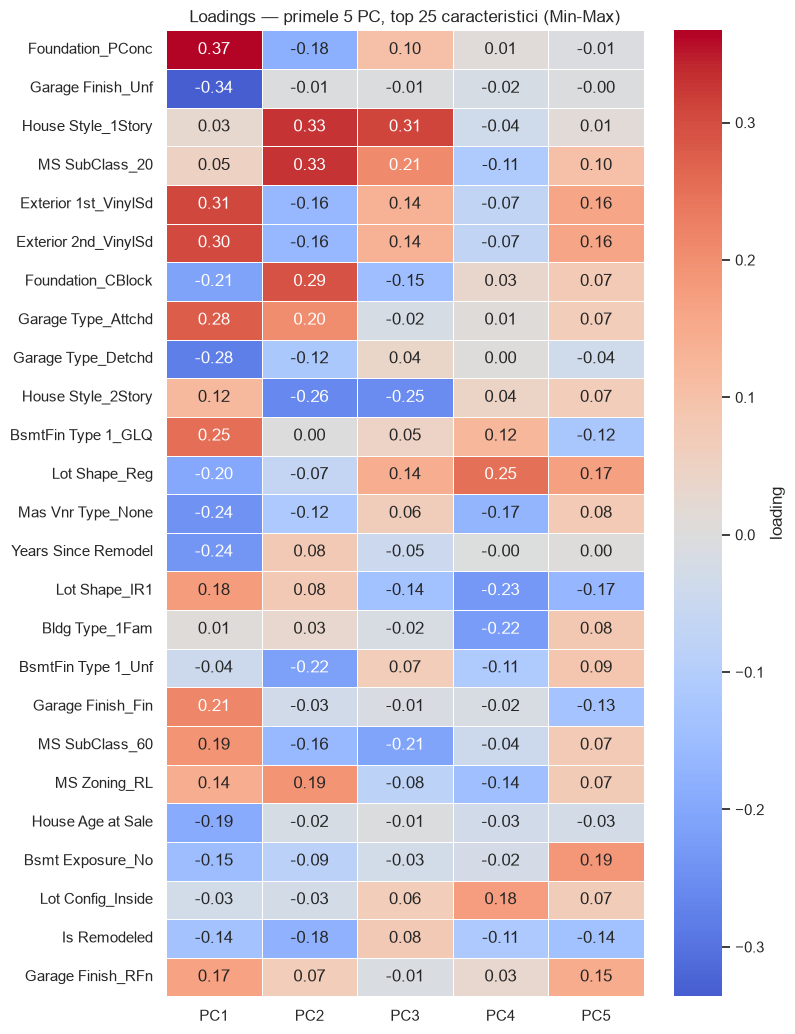

In [16]:
def compute_loadings(name, n_pc=10):
    p = pca_full[name]
    names = pipelines[name].named_steps["prep"].get_feature_names_out()
    L = p.components_.T * np.sqrt(p.explained_variance_)
    return pd.DataFrame(L[:, :n_pc], index=names,
                        columns=[f"PC{i+1}" for i in range(n_pc)])


def plot_loadings_heatmap(name, n_pc=5, top_n=25):
    L = compute_loadings(name, n_pc)
    top = L.abs().max(axis=1).sort_values(ascending=False).head(top_n).index
    plt.figure(figsize=(8, 0.34 * top_n + 2))
    sns.heatmap(L.loc[top], cmap="coolwarm", center=0, annot=True, fmt=".2f",
                linewidths=0.4, cbar_kws={"label": "loading"})
    plt.title(f"Loadings — primele {n_pc} PC, top {top_n} caracteristici ({name})")
    plt.tight_layout()
    plt.show()


loadings_df = compute_loadings(MAIN, n_pc=10)
plot_loadings_heatmap(MAIN, n_pc=5, top_n=25)

In [17]:
# Cele mai influente caracteristici pentru primele 3 componente
for pc in ["PC1", "PC2", "PC3"]:
    s = loadings_df[pc].sort_values()
    print(f"\n=== {pc} (varianță explicată: {evr[int(pc[2:])-1]:.2%}) ===")
    print("Cele mai negative:"); print(s.head(6).round(3).to_string())
    print("Cele mai pozitive:"); print(s.tail(6).round(3).to_string())


=== PC1 (varianță explicată: 12.14%) ===
Cele mai negative:
Garage Finish_Unf     -0.336
Garage Type_Detchd    -0.276
Mas Vnr Type_None     -0.243
Years Since Remodel   -0.236
Foundation_CBlock     -0.212
Lot Shape_Reg         -0.199
Cele mai pozitive:
Garage Finish_Fin       0.214
BsmtFin Type 1_GLQ      0.253
Garage Type_Attchd      0.277
Exterior 2nd_VinylSd    0.304
Exterior 1st_VinylSd    0.308
Foundation_PConc        0.367

=== PC2 (varianță explicată: 7.31%) ===
Cele mai negative:
House Style_2Story     -0.261
BsmtFin Type 1_Unf     -0.216
Foundation_PConc       -0.184
Is Remodeled           -0.175
Exterior 1st_VinylSd   -0.161
Exterior 2nd_VinylSd   -0.160
Cele mai pozitive:
Neighborhood_NAmes    0.156
MS Zoning_RL          0.193
Garage Type_Attchd    0.204
Foundation_CBlock     0.293
MS SubClass_20        0.329
House Style_1Story    0.330

=== PC3 (varianță explicată: 4.42%) ===
Cele mai negative:
House Style_2Story     -0.255
MS SubClass_60         -0.206
Foundation_CBlock  

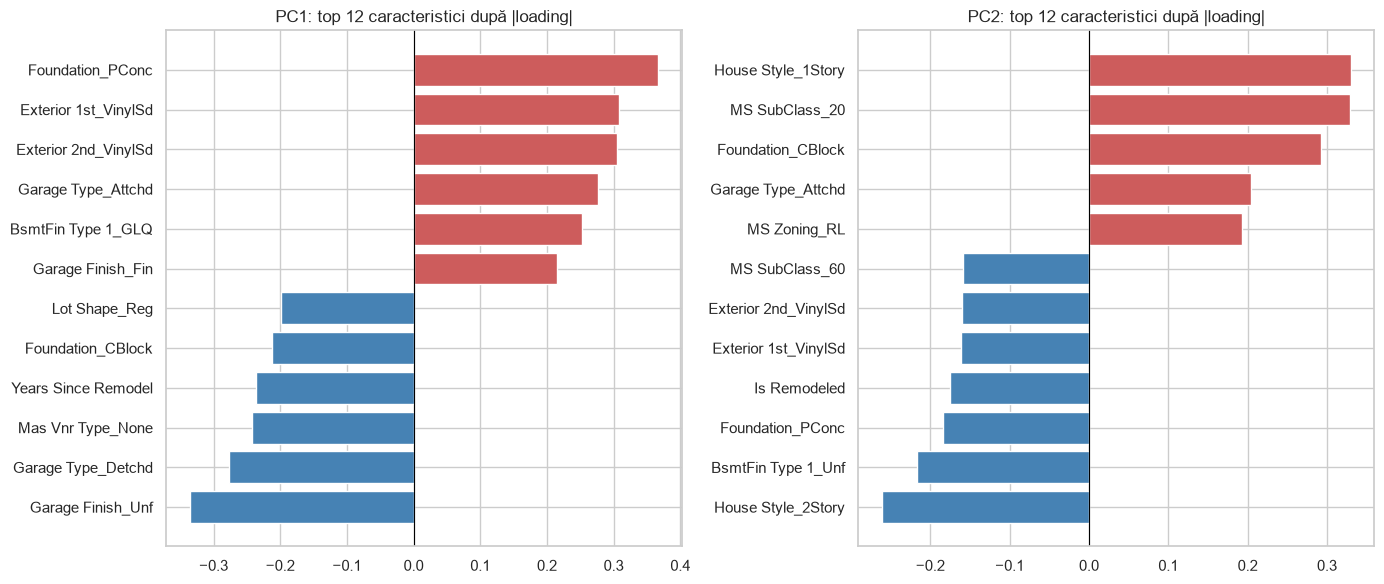

In [18]:
# Bară orizontală pentru PC1 și PC2 (cele mai importante 12 caracteristici după |loading|)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, pc in zip(axes, ["PC1", "PC2"]):
    s = loadings_df[pc]
    top = s.reindex(s.abs().sort_values(ascending=False).head(12).index).sort_values()
    ax.barh(top.index, top.values, color=np.where(top.values > 0, "indianred", "steelblue"))
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{pc}: top 12 caracteristici după |loading|")
plt.tight_layout()
plt.show()

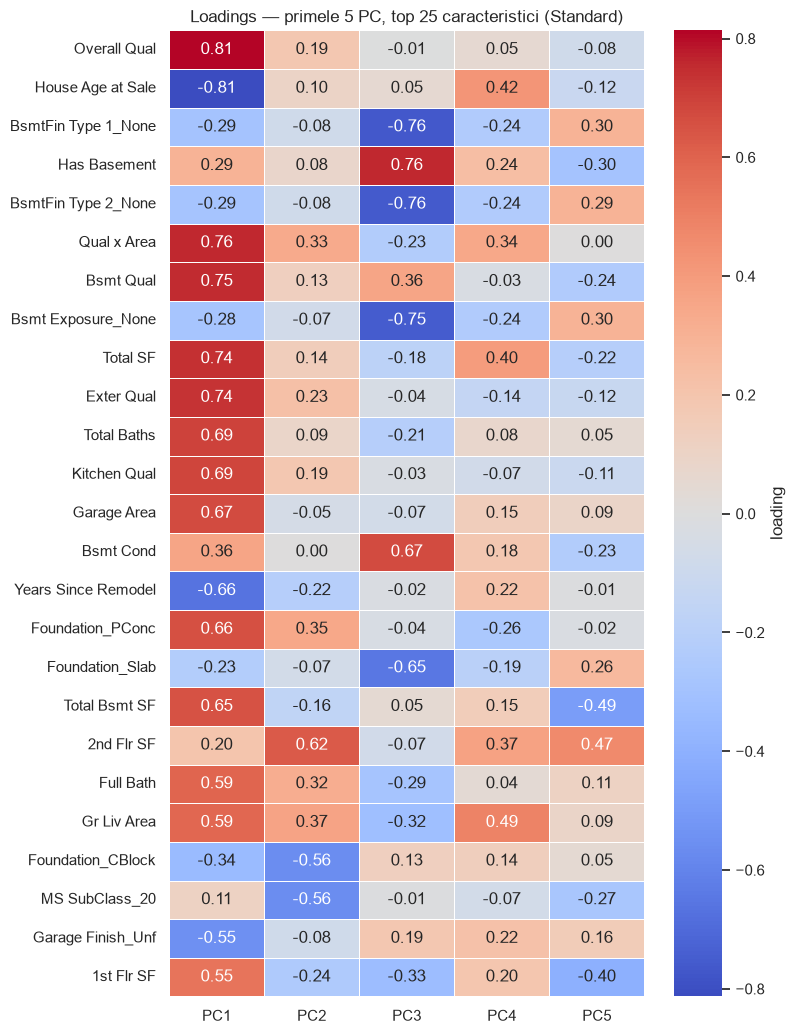

In [19]:
# Același heatmap pentru scalarea Standard (aici loadings = corelații) — pentru comparație
plot_loadings_heatmap("Standard", n_pc=5, top_n=25)

## Task 1.5 — Case fictive și inferență

In [20]:
# Casa "tipică" = mediană (numerice) / modă (categorice) pe tot setul
template = {
    c: (X_raw[c].median() if c in numeric_features else X_raw[c].mode()[0])
    for c in X_raw.columns
}

QUAL_TEXT = {0: "None", 1: "Po", 2: "Fa", 3: "TA", 4: "Gd", 5: "Ex"}


MS_PREFIX = "MS_" if str(template["MS SubClass"]).startswith("MS_") else ""


def make_house(name, living_1st, living_2nd=0, basement=0, bedrooms=3,
               full_bath=1, half_bath=0, overall_qual=5, overall_cond=5,
               qual_level=3, age=30, years_since_remodel=None, lot_area=8000,
               garage_area=0, fireplaces=0, neighborhood="NAmes"):
    """Construiește o casă coerentă: recalculează și coloanele derivate din curățare."""
    h = dict(template)

    def setv(col, val):
        if col in h:
            h[col] = val

    def setcat(col, val):
        if col in h and val in set(X_raw[col].unique()):
            h[col] = val

    def setq(col, level):
        # scala de calitate: numerică 0-5 sau text (Po..Ex), după cum e în setul tău
        if col in h:
            h[col] = int(level) if col in numeric_features else QUAL_TEXT[int(level)]

    if years_since_remodel is None:
        years_since_remodel = age

    # dimensiuni
    setv("1st Flr SF", living_1st); setv("2nd Flr SF", living_2nd)
    setv("Low Qual Fin SF", 0)
    gr_liv = living_1st + living_2nd
    setv("Gr Liv Area", gr_liv)
    setv("Lot Area", lot_area); setv("Neighborhood", neighborhood)
    setv("Overall Qual", overall_qual); setv("Overall Cond", overall_cond)

    setcat("House Style", "2Story" if living_2nd > 0 else "1Story")
    setcat("MS SubClass", MS_PREFIX + ("60" if living_2nd > 0 else "20"))

    if basement == 0:
        setcat("Foundation", "Slab")
    else:
        setcat("Foundation", "PConc" if age < 25 else "CBlock")

    setcat("Exterior 1st", "VinylSd" if age < 30 else "Wd Sdng")
    setcat("Exterior 2nd", "VinylSd" if age < 30 else "Wd Sdng")

    # camere și băi
    for col in ["Bedroom AbvGr", "Bedroom"]:
        setv(col, bedrooms)
    for col in ["TotRms AbvGrd", "TotRmsAbvGrd"]:
        setv(col, bedrooms + 3)
    setv("Full Bath", full_bath); setv("Half Bath", half_bath)
    setv("Bsmt Full Bath", 0); setv("Bsmt Half Bath", 0)

    # subsol
    setv("Total Bsmt SF", basement); setv("Bsmt Unf SF", basement)
    setv("BsmtFin SF 1", 0); setv("BsmtFin SF 2", 0)
    setv("Has Basement", int(basement > 0))
    if basement == 0:
        for col in ["Bsmt Exposure", "BsmtFin Type 1", "BsmtFin Type 2"]:
            setv(col, "None")
    setq("Bsmt Qual", qual_level if basement > 0 else 0)
    setq("Bsmt Cond", 3 if basement > 0 else 0)

    # garaj
    setv("Garage Area", garage_area); setv("Has Garage", int(garage_area > 0))
    setv("Garage Cars", int(np.ceil(garage_area / 250)))
    setv("Garage Type", "Attchd" if garage_area > 0 else "None")
    setv("Garage Finish", "Unf" if garage_area > 0 else "None")
    setq("Garage Qual", 3 if garage_area > 0 else 0)
    setq("Garage Cond", 3 if garage_area > 0 else 0)

    # șemineu și calități
    setv("Fireplaces", fireplaces)
    setq("Fireplace Qu", qual_level if fireplaces > 0 else 0)
    for col in ["Exter Qual", "Kitchen Qual", "Heating QC"]:
        setq(col, qual_level)
    setq("Exter Cond", 3)

    # coloane derivate din curățare / feature engineering (dacă există în setul tău)
    setv("House Age at Sale", age)
    setv("Years Since Remodel", years_since_remodel)
    setv("Is Remodeled", int(years_since_remodel != age))
    setv("Total SF", basement + gr_liv)
    setv("Qual x Area", overall_qual * gr_liv)
    setv("Total Baths", full_bath + 0.5 * half_bath)
    porch_cols = ["Open Porch SF", "Enclosed Porch", "3Ssn Porch", "Screen Porch", "Wood Deck SF"]
    setv("Total Porch SF", sum(h[c] for c in porch_cols if c in h))

    return pd.Series(h, name=name)


houses = [
    make_house("1. Mică și veche", living_1st=750, basement=600, bedrooms=2,
               overall_qual=4, qual_level=2, age=70, years_since_remodel=40,
               lot_area=6000, neighborhood="OldTown"),
    make_house("2. Casă de familie", living_1st=1000, living_2nd=800, basement=1000,
               bedrooms=3, full_bath=2, half_bath=1, overall_qual=6, qual_level=3,
               age=20, lot_area=9000, garage_area=480, fireplaces=1, neighborhood="CollgCr"),
    make_house("3. Casă de lux", living_1st=1800, living_2nd=1200, basement=1800,
               bedrooms=4, full_bath=3, half_bath=1, overall_qual=9, qual_level=5,
               age=3, lot_area=15000, garage_area=900, fireplaces=2, neighborhood="NridgHt"),
    make_house("4. Mare, dar slabă calitativ", living_1st=1500, living_2nd=900, basement=800,
               bedrooms=4, full_bath=1, overall_qual=3, overall_cond=3, qual_level=2,
               age=90, years_since_remodel=90, lot_area=10000, neighborhood="OldTown"),
    make_house("5. Nouă, mică, calitate bună", living_1st=1100, basement=0,
               bedrooms=2, full_bath=2, overall_qual=8, qual_level=4, age=1,
               lot_area=3500, garage_area=400, neighborhood="CollgCr"),
    make_house("6. Extremă (în afara datelor)", living_1st=3500, living_2nd=2500, basement=2500,
               bedrooms=6, full_bath=4, half_bath=2, overall_qual=10, qual_level=5,
               age=0, lot_area=40000, garage_area=1200, fireplaces=3, neighborhood="NridgHt"),
]

houses_df = pd.DataFrame(houses)[X_raw.columns]
display(houses_df[["Gr Liv Area", "Total Bsmt SF", "Overall Qual", "Lot Area",
                   "Garage Area", "Neighborhood",
                   "House Style", "MS SubClass", "Foundation", "Exterior 1st"]])

,Gr Liv Area,Total Bsmt SF,Overall Qual,Lot Area,Garage Area,Neighborhood,House Style,MS SubClass,Foundation,Exterior 1st
1. Mică și veche,750,600,4,6000,0,OldTown,1Story,20,CBlock,Wd Sdng
2. Casă de familie,1800,1000,6,9000,480,CollgCr,2Story,60,PConc,VinylSd
3. Casă de lux,3000,1800,9,15000,900,NridgHt,2Story,60,PConc,VinylSd
"4. Mare, dar slabă calitativ",2400,800,3,10000,0,OldTown,2Story,60,CBlock,Wd Sdng
"5. Nouă, mică, calitate bună",1100,0,8,3500,400,CollgCr,1Story,20,Slab,VinylSd
6. Extremă (în afara datelor),6000,2500,10,40000,1200,NridgHt,2Story,60,PConc,VinylSd


In [21]:
# Inferența corectă: același pipeline (encoding + scalare învățate pe date) + pca.transform
pipe_main = pipelines[MAIN]

houses_scaled = pipe_main.transform(houses_df)      # encoding + Min-Max (parametrii din setul real)
houses_pca = pca_main.transform(houses_scaled)      # proiecție pe axele existente

print("Forma după pipeline:", houses_scaled.shape, "| după PCA:", houses_pca.shape)
print(f"Valori Min-Max în afara [0, 1]: {int(((houses_scaled < 0) | (houses_scaled > 1)).sum())} "
      "(normal pentru valori în afara intervalului văzut la antrenare)")

# Verificare manuală: pca.transform = (x - media) @ componentele^T
manual = (houses_scaled - pca_main.mean_) @ pca_main.components_.T
assert np.allclose(manual, houses_pca)
print("Verificare formulă PCA: OK")

scores = pd.DataFrame(houses_pca[:, :5], index=houses_df.index,
                      columns=[f"PC{i+1}" for i in range(5)])
display(scores.round(3))

Forma după pipeline: (6, 277) | după PCA: (6, 277)
Valori Min-Max în afara [0, 1]: 6 (normal pentru valori în afara intervalului văzut la antrenare)
Verificare formulă PCA: OK


,PC1,PC2,PC3,PC4,PC5
1. Mică și veche,-1.286,0.440,0.726,-0.111,0.182
2. Casă de familie,0.817,-1.058,-0.352,0.167,1.097
3. Casă de lux,1.309,-1.217,-0.344,0.182,0.727
"4. Mare, dar slabă calitativ",-1.099,-0.496,-0.795,0.232,0.387
"5. Nouă, mică, calitate bună",0.075,0.517,1.016,-0.151,0.995
6. Extremă (în afara datelor),1.607,-1.433,-0.616,0.140,0.595


In [22]:
# Ce se întâmplă dacă sărim peste scalare? Demonstrație a erorii frecvente.
houses_no_scale = pipe_main.named_steps["prep"].transform(houses_df)
wrong = pca_main.transform(houses_no_scale)
compare = pd.DataFrame({
    "PC1 corect": houses_pca[:, 0],
    "PC1 fără scalare": wrong[:, 0],
}, index=houses_df.index)
display(compare.round(2))

,PC1 corect,PC1 fără scalare
1. Mică și veche,-1.29,360.93
2. Casă de familie,0.82,1096.89
3. Casă de lux,1.31,2439.87
"4. Mare, dar slabă calitativ",-1.10,873.36
"5. Nouă, mică, calitate bună",0.08,732.68
6. Extremă (în afara datelor),1.61,5121.16


In [23]:
# Verificare intuitivă: ce case reale sunt cele mai apropiate în spațiul PCA (95% varianță)?
k95 = n_components[MAIN][0.95]
nn = NearestNeighbors(n_neighbors=10).fit(Z_full[MAIN][:, :k95])
_, idx = nn.kneighbors(houses_pca[:, :k95])

summary = []
for i, name in enumerate(houses_df.index):
    nb = idx[i]
    summary.append({
        "Casă fictivă": name,
        "Preț median al celor 10 vecini ($)": int(y_price.iloc[nb].median()),
        "Clasa predominantă a vecinilor": y_class.iloc[nb].value_counts().idxmax(),
    })
display(pd.DataFrame(summary))

,Casă fictivă,Preț median al celor 10 vecini ($),Clasa predominantă a vecinilor
0,1. Mică și veche,120800,100k-130k
1,2. Casă de familie,211500,180k-250k
2,3. Casă de lux,233500,180k-250k
3,"4. Mare, dar slabă calitativ",111500,100k-130k
4,"5. Nouă, mică, calitate bună",117000,100k-130k
5,6. Extremă (în afara datelor),253950,250k-400k


### De ce trebuie transformat punctul nou înainte de inferență?

PCA nu e o simplă „comprimare”: definește un **sistem nou de axe** (vectorii proprii ai matricei de covarianță a datelor de antrenare), iar modelul K-Means a fost antrenat **în acel spațiu**. Un punct nou are sens doar dacă e exprimat în aceleași coordonate:

1. **Encoding și scalare cu parametrii din antrenare.** Casa nouă trebuie să aibă exact aceleași coloane, în aceeași ordine, și aceeași scală (minimul și maximul din setul real). Dacă am scala punctul separat (sau am refolosi alte valori), 1 mp ar avea alt „preț” decât în date, iar proiecția ar fi fără sens. Fără scalare, trăsăturile cu valori mari (suprafețe în mp) domină PC1.
2. **`pca.transform` = centrare + proiecție.** Calculează `(x − media_antrenare) · Vᵀ`, adică proiectează pe vectorii proprii deja găsiți. Nu recalculăm PCA pe punctul nou: un singur punct nu are covarianță, iar dacă am reface PCA, axele s-ar schimba și centroizii K-Means ar fi într-un spațiu diferit.
3. **Comparabilitate.** Distanțele către centroizi se măsoară în spațiul PCA. Doar un punct proiectat pe aceleași axe poate fi comparat cu ei.

Observație: valori extreme (casa 6) pot ieși din intervalul [0, 1] la Min-Max și pot cădea departe de toate datele. Proiecția rămâne definită matematic, dar atribuirea la un cluster e o extrapolare, deci mai puțin de încredere.

## Salvare pentru colega (K-Means)

In [ ]:
artifacts = {
    "pipelines": pipelines,           # encoding + scalare, ajustate pe tot setul
    "pca_full": pca_full,             # PCA cu toate componentele, per variantă
    "thresholds": thresholds,
    "n_components": n_components,
    "reduced": reduced,               # seturile reduse: reduced[(variantă, prag)]
    "y_price": y_price,
    "y_class": y_class,
    "y_class_codes": y_class_codes,
    "class_names": class_names,
    "feature_names": feature_names,
    "houses_df": houses_df,           # case fictive (date brute)
    "houses_pca": houses_pca,         # case fictive proiectate (Min-Max, toate PC)
}
joblib.dump(artifacts, "data/pca_artifacts.joblib")
print("Salvat: data/pca_artifacts.joblib")
print("Colega încarcă cu: artifacts = joblib.load('data/pca_artifacts.joblib')")